# 04 Analysis and charts

**In:** `orders_qu.csv`, `orderlines_qu.csv` (made by `02_data-quality.ipynb`) and `products_categorised.csv` (made by `03_product-categories.ipynb`), folder `data/clean-data`.
**Out:** the 4 charts used in the board presentation (`documentation/slides/eniac-board-presentation.pdf`).

The question: **is discounting good for Eniac?** We look at sales, revenue and discounts from four angles: over time, by price, by product category and by discount size.

**Keep in mind:**
- Completed orders only, January 2017 to 14 March 2018.
- Every sale of €1,000 or more is missing: those prices were broken and removed in `01_data-cleaning.ipynb`.
- There is no cost data, so we measure **revenue** (money coming in), not profit.
- **Discount** = (list price − price paid) ÷ list price, for each order line. **Average discount** = the plain average over order lines: every line counts once, whatever its price or quantity.

## Setup

In [1]:
import pandas as pd
import seaborn as sns

In [2]:
# show numbers with 2 decimals, and allow long tables
pd.set_option("display.float_format", lambda x: "%.2f" % x)
pd.set_option("display.max_rows", 1000)

# one clean style for every chart, and the same 3 colours on every slide
sns.set_theme(style="white")
BLUE = "#2b5c8f"    # items sold
GREEN = "#126835"   # revenue
RED = "#C0392B"     # discount

In [3]:
# orders_qu.csv (my Drive: data/clean-data)
url = "https://drive.google.com/file/d/125afYtvpEKVd6rdTp9vEMami6y19XgGL/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id=" + url.split("/")[-2]
orders_qu = pd.read_csv(path)

# orderlines_qu.csv (my Drive: data/clean-data)
url = "https://drive.google.com/file/d/1wr9tbay0O8xtZs9DXGLRHlZZJB__KQcr/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id=" + url.split("/")[-2]
orderlines_qu = pd.read_csv(path)

# products_categorised.csv (my Drive: data/clean-data)
url = "https://drive.google.com/file/d/1c4Jh5XH9teBs1de19P0w0RunPGArSAI0/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id=" + url.split("/")[-2]
products_categorised = pd.read_csv(path)

In [4]:
# size of each table (rows, columns)
orders_qu.shape, orderlines_qu.shape, products_categorised.shape

((40985, 4), (53231, 7), (9992, 9))

## Step 1: One table with everything we need

In [5]:
orders_s1 = orders_qu.copy()
orderlines_s1 = orderlines_qu.copy()
products_s1 = products_categorised.copy()

In [6]:
# a CSV file stores dates as text, so turn them back into dates
orders_s1["created_date"] = pd.to_datetime(orders_s1["created_date"])

In [7]:
# add the list price and category of each product, and the date of each order, to every order line
lines_s1 = orderlines_s1.merge(products_s1[["sku", "price", "grouped_category"]], on="sku", how="left")
lines_s1 = lines_s1.merge(orders_s1[["order_id", "created_date"]], left_on="id_order", right_on="order_id", how="left")

# every order line should have found its product and its order
lines_s1.shape, lines_s1["price"].isna().sum(), lines_s1["created_date"].isna().sum()

((53231, 11), np.int64(0), np.int64(0))

In [8]:
# discount of each order line, in %: how far below the list price it was sold
lines_s1["discount_pct"] = (lines_s1["price"] - lines_s1["unit_price"]) / lines_s1["price"] * 100

lines_s1[["sku", "price", "unit_price", "product_quantity", "unit_price_total", "discount_pct"]].head()

,sku,price,unit_price,product_quantity,unit_price_total,discount_pct
0,OWC0100,60.99,47.49,1,47.49,22.13
1,IOT0014,22.95,18.99,1,18.99,17.25
2,APP0700,89.00,72.19,1,72.19,18.89
3,CRU0039-A,76.99,60.90,1,60.90,20.90
4,PEB0015,299.99,142.49,1,142.49,52.50


**What we see:** all 53,231 order lines found their product and their order. Each line now has its list price (`price`), the price paid (`unit_price`), the revenue (`unit_price_total` = price paid × quantity) and its discount in %.

## Step 2: How many sales are discounted, and by how much?

In [9]:
# total revenue (sum of all order lines)
lines_s1["unit_price_total"].sum()

np.float64(7817204.399999999)

In [10]:
# share of order lines sold below, at, and above the list price, in %
sold_below = (lines_s1["discount_pct"] > 0).mean() * 100
sold_at = (lines_s1["discount_pct"] == 0).mean() * 100
sold_above = (lines_s1["discount_pct"] < 0).mean() * 100
round(sold_below, 1), round(sold_at, 1), round(sold_above, 1)

(np.float64(92.8), np.float64(4.2), np.float64(3.0))

In [11]:
# the same, counting items sold (quantity) instead of order lines
items_below = lines_s1.loc[lines_s1["discount_pct"] > 0, "product_quantity"].sum() / lines_s1["product_quantity"].sum() * 100
round(items_below, 1)

np.float64(92.8)

In [12]:
# share of the different products sold that were discounted at least once, in %
products_sold = lines_s1["sku"].nunique()
products_discounted = lines_s1.loc[lines_s1["discount_pct"] > 0, "sku"].nunique()
products_sold, products_discounted, round(products_discounted / products_sold * 100, 1)

(5098, 4906, 96.2)

In [13]:
# average discount per order line, and the median
lines_s1["discount_pct"].mean(), lines_s1["discount_pct"].median()

(np.float64(21.37796131577819), 17.648096946879228)

In [14]:
# total discount in € compared with the total list value of everything sold
discount_eur = ((lines_s1["price"] - lines_s1["unit_price"]) * lines_s1["product_quantity"]).sum()
list_value = (lines_s1["price"] * lines_s1["product_quantity"]).sum()
discount_eur, list_value, discount_eur / list_value * 100

(np.float64(1525222.46),
 np.float64(9342426.86),
 np.float64(16.325762918522866))

**What we see:**
- Total revenue is €7.82M.
- **93% of order lines** (and 93% of items) were sold below list price. 4% were sold at list price and 3% **above** it.
- 96% of the 5,098 different products sold were discounted at least once. Discounting is the norm at Eniac.
- The average discount per order line is **21.4%** (median 17.6%).
- In euros, discounts took €1.53M off a list value of €9.34M: **16.3%**. This is lower than 21.4% because expensive items get smaller discounts, and they weigh more in euros.

## Step 3: Chart 1, over time

In [15]:
# items sold, revenue and average discount per month
monthly = lines_s1.groupby(lines_s1["created_date"].dt.to_period("M")).agg(
    items_sold=("product_quantity", "sum"),
    revenue=("unit_price_total", "sum"),
    avg_discount=("discount_pct", "mean"),
)
monthly

,items_sold,revenue,avg_discount
created_date,,,
2017-01,6808,604091.87,24.87
2017-02,2964,332612.30,19.54
2017-03,241,24856.02,19.05
2017-04,2115,228090.63,18.26
2017-05,2564,331214.98,15.40
2017-06,2046,286575.67,17.16
2017-07,4631,599404.93,24.98
2017-08,3027,379560.32,20.49
2017-09,2771,387942.85,20.02


**What we see:**
- Items sold and revenue rise and fall together. Both peak in November 2017 (Black Friday: 9,552 items, €1.50M), stay high in December and January, then fall.
- The average discount stays between 15% and 25% in every month. It does not jump when sales jump.
- March 2017 has only 241 items: most of that month's data is missing. March 2018 stops on the 14th.

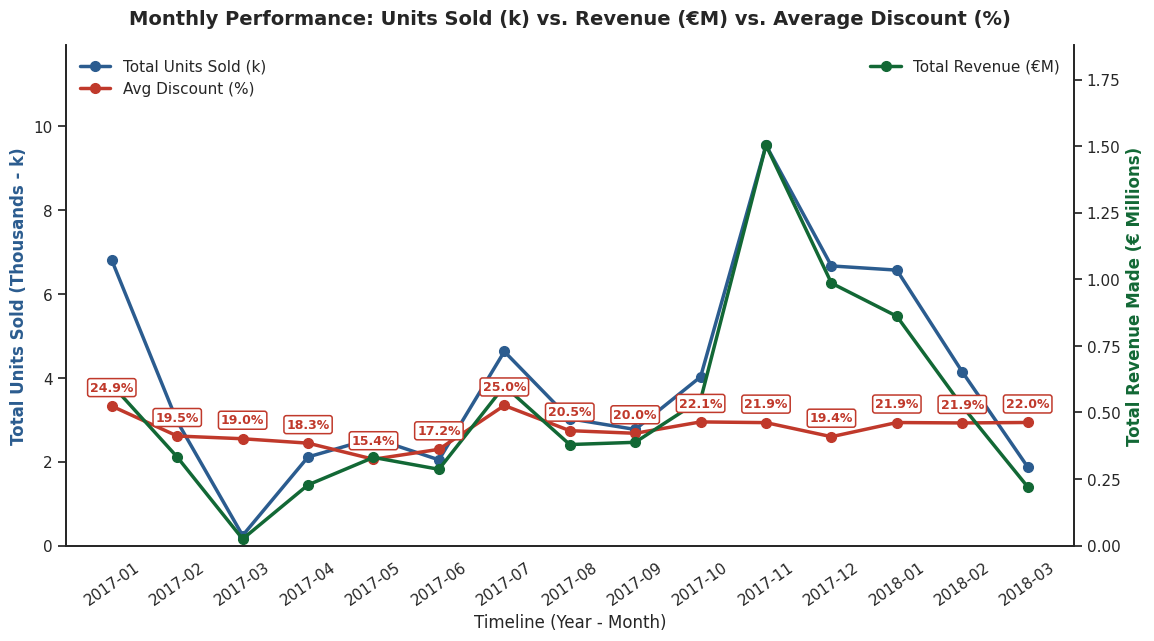

In [16]:
# chart 1: items sold (blue, left axis) and revenue (green, right axis) per month,
# with the average discount written in red above a red line

chart1 = monthly.copy()
chart1.index = chart1.index.astype(str)          # "2017-01" etc. as labels
chart1["items_k"] = chart1["items_sold"] / 1000  # thousands
chart1["revenue_m"] = chart1["revenue"] / 1000000  # millions

# the discount has no axis of its own: draw its line low on the chart (35% of the height), and write the real % above each point
chart1["discount_line"] = chart1["avg_discount"] * (chart1["items_k"].max() * 0.35) / chart1["avg_discount"].max()

ax = chart1.plot(kind="line", y=["items_k", "discount_line", "revenue_m"], secondary_y=["revenue_m"],
                 color=[BLUE, RED, GREEN], marker="o", markersize=7, linewidth=2.5, figsize=(13, 6.5))
ax.set_title("Monthly Performance: Units Sold (k) vs. Revenue (€M) vs. Average Discount (%)", fontsize=14, fontweight="bold", pad=15)
sns.despine(top=True, right=False)

# room at the top, so the lines don't touch the legends
max_items = chart1["items_k"].max()
max_revenue = chart1["revenue_m"].max()
ax.set_ylim(0, max_items * 1.25)
ax.right_ax.set_ylim(0, max_revenue * 1.25)

# the real discount % in a small red box above each red point
for i, (month, row) in enumerate(chart1.iterrows()):
    y = row["discount_line"] / max_items * max_revenue + max_revenue * 0.03
    ax.right_ax.text(i, y, f"{row['avg_discount']:.1f}%", color=RED, fontsize=9, fontweight="bold", ha="center", va="bottom",
                     zorder=10, bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor=RED, linewidth=1.1))

ax.set_ylabel("Total Units Sold (Thousands - k)", color=BLUE, fontsize=12, fontweight="bold")
ax.right_ax.set_ylabel("Total Revenue Made (€ Millions)", color=GREEN, fontsize=12, fontweight="bold")
ax.set_xlabel("Timeline (Year - Month)", fontsize=12)
ax.set_xticks(range(len(chart1)))
ax.set_xticklabels(chart1.index, rotation=35)
ax.legend(["Total Units Sold (k)", "Avg Discount (%)"], loc="upper left", frameon=False)
ax.right_ax.legend(["Total Revenue (€M)"], loc="upper right", frameon=False);

**Slide message:** sales follow the calendar. The average discount stays near 20% all year, so the calendar moves sales much more than the size of the discount.

## Step 4: Chart 2, by price

In [17]:
# put each order line in a price band, using the product's list price
price_bins = [0, 50, 150, 500, 1000, float("inf")]
price_labels = ["<=50 budget essentials", ">50€ standard accessories", ">150€ mid-range tech", ">500€ premium hardware", ">1000€ ultra-premium"]
lines_s1["price_band"] = pd.cut(lines_s1["price"], bins=price_bins, labels=price_labels)

# items sold, revenue, share of revenue and average discount per price band
price_bands = lines_s1.groupby("price_band", observed=False).agg(
    items_sold=("product_quantity", "sum"),
    revenue=("unit_price_total", "sum"),
    avg_discount=("discount_pct", "mean"),
)
price_bands["revenue_share"] = price_bands["revenue"] / price_bands["revenue"].sum() * 100
price_bands

,items_sold,revenue,avg_discount,revenue_share
price_band,,,,
<=50 budget essentials,21327,458824.89,26.28,5.87
>50€ standard accessories,20932,1500440.81,22.29,19.19
>150€ mid-range tech,13676,3192782.74,15.95,40.84
>500€ premium hardware,3719,2363629.02,9.78,30.24
>1000€ ultra-premium,357,301526.94,24.27,3.86


**What we see:**
- Items under €50 sell the most (21,327) and get the biggest average discount (26.3%), but bring in only 5.9% of revenue.
- Items from €150 to €1,000 bring in €5.56M, **71% of revenue**, with smaller discounts (16.0% and 9.8%).
- The "over €1,000" band only holds items with a list price over €1,000 that were **sold** for less than €1,000 (all sales of €1,000 or more are missing). It can't be judged.

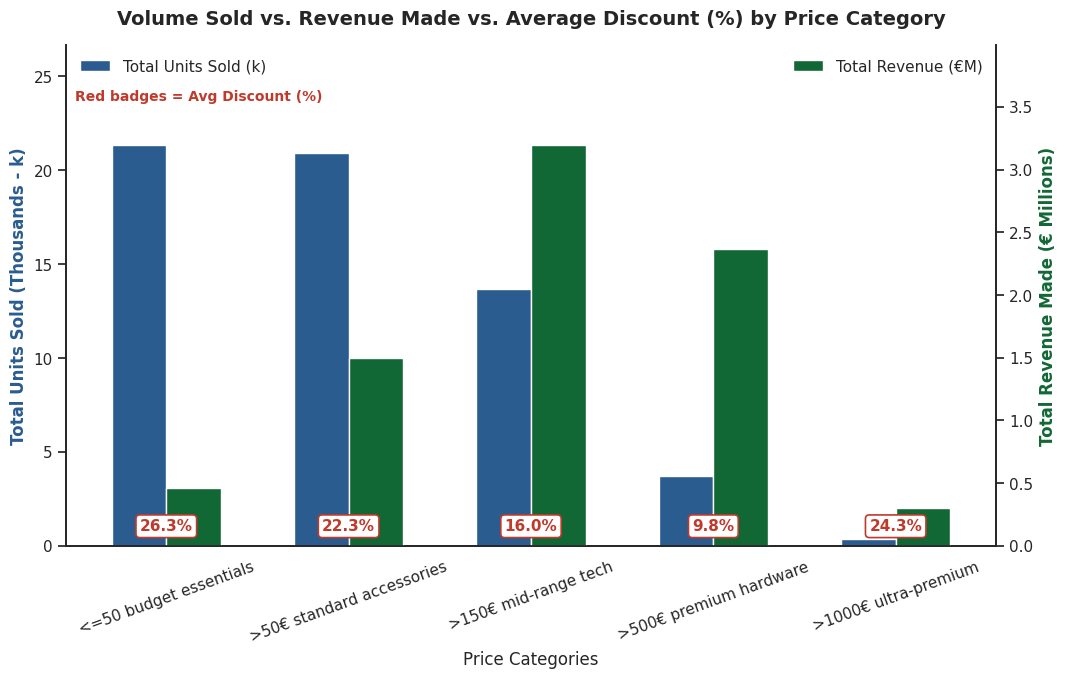

In [18]:
# chart 2: items sold (blue) and revenue (green) per price band, with the average discount in red at the bottom
chart2 = price_bands.copy()
chart2["items_k"] = chart2["items_sold"] / 1000
chart2["revenue_m"] = chart2["revenue"] / 1000000

ax = chart2.plot(kind="bar", y=["items_k", "revenue_m"], secondary_y=["revenue_m"], color=[BLUE, GREEN], figsize=(12, 6.5), width=0.6)
ax.set_title("Volume Sold vs. Revenue Made vs. Average Discount (%) by Price Category", fontsize=14, fontweight="bold", pad=15)
sns.despine(top=True, right=False)

max_items = chart2["items_k"].max()
max_revenue = chart2["revenue_m"].max()
ax.set_ylim(0, max_items * 1.25)
ax.right_ax.set_ylim(0, max_revenue * 1.25)

for i, (band, row) in enumerate(chart2.iterrows()):
    ax.right_ax.text(i, max_revenue * 0.03, f"{row['avg_discount']:.1f}%", color=RED, fontsize=11, fontweight="bold", ha="center", va="bottom",
                     zorder=10, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=RED, linewidth=1.2))

ax.set_ylabel("Total Units Sold (Thousands - k)", color=BLUE, fontsize=12, fontweight="bold")
ax.right_ax.set_ylabel("Total Revenue Made (€ Millions)", color=GREEN, fontsize=12, fontweight="bold")
ax.set_xlabel("Price Categories", fontsize=12)
ax.set_xticklabels(chart2.index, rotation=20)
ax.legend(["Total Units Sold (k)"], loc="upper left", frameon=False)
ax.right_ax.legend(["Total Revenue (€M)"], loc="upper right", frameon=False)
ax.right_ax.text(0.01, 0.89, "Red badges = Avg Discount (%)", transform=ax.right_ax.transAxes, color=RED, fontsize=10, fontweight="bold");

**Slide message:** cheap items get the biggest discounts but bring in little revenue. The higher the price of an item, the more euros each percent of discount costs.

## Step 5: Chart 3, by product category

In [19]:
# items sold, revenue and average discount per category, biggest revenue first
categories = lines_s1.groupby("grouped_category").agg(
    items_sold=("product_quantity", "sum"),
    revenue=("unit_price_total", "sum"),
    avg_discount=("discount_pct", "mean"),
).sort_values("revenue", ascending=False)
categories

,items_sold,revenue,avg_discount
grouped_category,,,
Storage & Memory,16750,2244098.77,17.49
iPhones & Smartphones,2339,1334817.39,9.33
"Peripherals, Smart Home & Gadgets",8403,811310.31,18.68
"Cases, Cables & Accessories",19002,698258.17,29.08
Monitors & Displays,1800,688211.41,12.10
"Audio, Wearables & Media Players",4437,665046.50,25.48
NAS & Servers,1189,471904.89,7.88
iPads & Tablets,667,386133.07,7.34
Mac & Computers,319,241279.51,22.57


**What we see:**
- Cases, Cables & Accessories sell the most items (19,002) with the biggest discount (29.1%), but bring in only €0.70M.
- iPhones & Smartphones are the opposite: 2,339 items, a 9.3% discount and €1.33M.
- Storage & Memory is the biggest earner: €2.24M at a 17.5% discount.
- Mac & Computers looks small (€0.24M) only because its sales of €1,000 or more are missing.

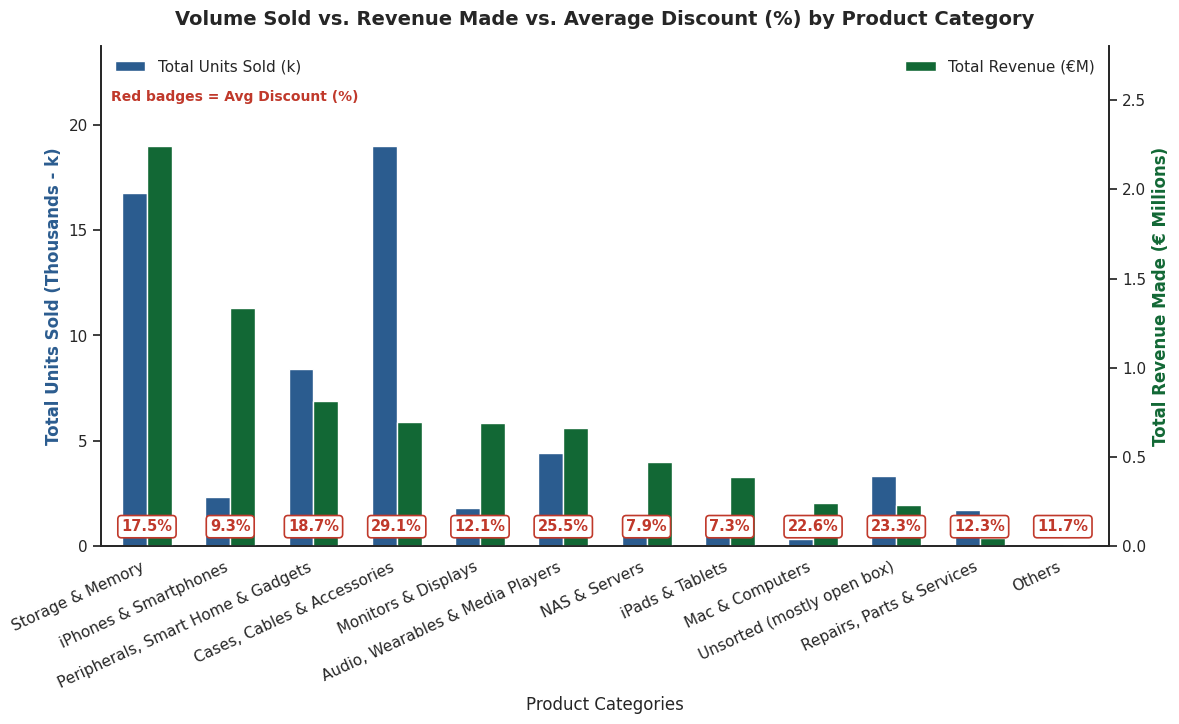

In [20]:
# chart 3: items sold (blue) and revenue (green) per category, with the average discount in red at the bottom
chart3 = categories.copy()
chart3["items_k"] = chart3["items_sold"] / 1000
chart3["revenue_m"] = chart3["revenue"] / 1000000

ax = chart3.plot(kind="bar", y=["items_k", "revenue_m"], secondary_y=["revenue_m"], color=[BLUE, GREEN], figsize=(13, 6.5), width=0.6)
ax.set_title("Volume Sold vs. Revenue Made vs. Average Discount (%) by Product Category", fontsize=14, fontweight="bold", pad=15)
sns.despine(top=True, right=False)

max_items = chart3["items_k"].max()
max_revenue = chart3["revenue_m"].max()
ax.set_ylim(0, max_items * 1.25)
ax.right_ax.set_ylim(0, max_revenue * 1.25)

for i, (category, row) in enumerate(chart3.iterrows()):
    ax.right_ax.text(i, max_revenue * 0.03, f"{row['avg_discount']:.1f}%", color=RED, fontsize=10.5, fontweight="bold", ha="center", va="bottom",
                     zorder=10, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=RED, linewidth=1.2))

ax.set_ylabel("Total Units Sold (Thousands - k)", color=BLUE, fontsize=12, fontweight="bold")
ax.right_ax.set_ylabel("Total Revenue Made (€ Millions)", color=GREEN, fontsize=12, fontweight="bold")
ax.set_xlabel("Product Categories", fontsize=12)
ax.set_xticklabels(chart3.index, rotation=25, ha="right")
ax.legend(["Total Units Sold (k)"], loc="upper left", frameon=False)
ax.right_ax.legend(["Total Revenue (€M)"], loc="upper right", frameon=False)
ax.right_ax.text(0.01, 0.89, "Red badges = Avg Discount (%)", transform=ax.right_ax.transAxes, color=RED, fontsize=10, fontweight="bold");

**Slide message:** accessories get the biggest discounts, phones and tablets the smallest. The products that earn the most are not the ones with the biggest discounts.

## Step 6: Chart 4, by discount size

In [21]:
# put each order line in a discount band
# the first band catches the lines sold ABOVE list price (negative discount), so every sale is counted
discount_bins = [-1000, -0.01, 0, 10, 20, 30, 40, 50, 1000]
discount_labels = ["Above list price", "No discount", ">0-10%", ">10-20%", ">20-30%", ">30-40%", ">40-50%", ">50%"]
lines_s1["discount_band"] = pd.cut(lines_s1["discount_pct"], bins=discount_bins, labels=discount_labels)

# check: every order line got a band (expected: 0)
lines_s1["discount_band"].isna().sum()

np.int64(0)

In [22]:
# share of items sold and share of revenue per discount band, in %
discount_bands = lines_s1.groupby("discount_band", observed=False).agg(
    items_sold=("product_quantity", "sum"),
    revenue=("unit_price_total", "sum"),
)
discount_bands["pct_items"] = discount_bands["items_sold"] / discount_bands["items_sold"].sum() * 100
discount_bands["pct_revenue"] = discount_bands["revenue"] / discount_bands["revenue"].sum() * 100
discount_bands

,items_sold,revenue,pct_items,pct_revenue
discount_band,,,,
Above list price,1772,331902.99,2.95,4.25
No discount,2569,243177.99,4.28,3.11
>0-10%,11693,2647204.05,19.48,33.86
>10-20%,17093,2546320.72,28.48,32.57
>20-30%,13004,1442741.84,21.67,18.46
>30-40%,4993,337477.84,8.32,4.32
>40-50%,3103,118619.77,5.17,1.52
>50%,5784,149759.20,9.64,1.92


In [23]:
# share of revenue from discounts of more than 0% and up to 20%
discount_bands.loc[[">0-10%", ">10-20%"], "pct_revenue"].sum()

np.float64(66.43711107259776)

**What we see:**
- Discounts up to 20% bring in **66.4% of revenue** (about two thirds) from 48% of the items sold.
- Discounts above 20% bring in 26% of revenue from 45% of the items. The deeper the discount, the less revenue each band brings.
- 3% of items were sold above list price (4.3% of revenue). In the presentation chart these sales were left out by mistake; here they have their own bar. The message doesn't change: it was 69% instead of 66.4%.

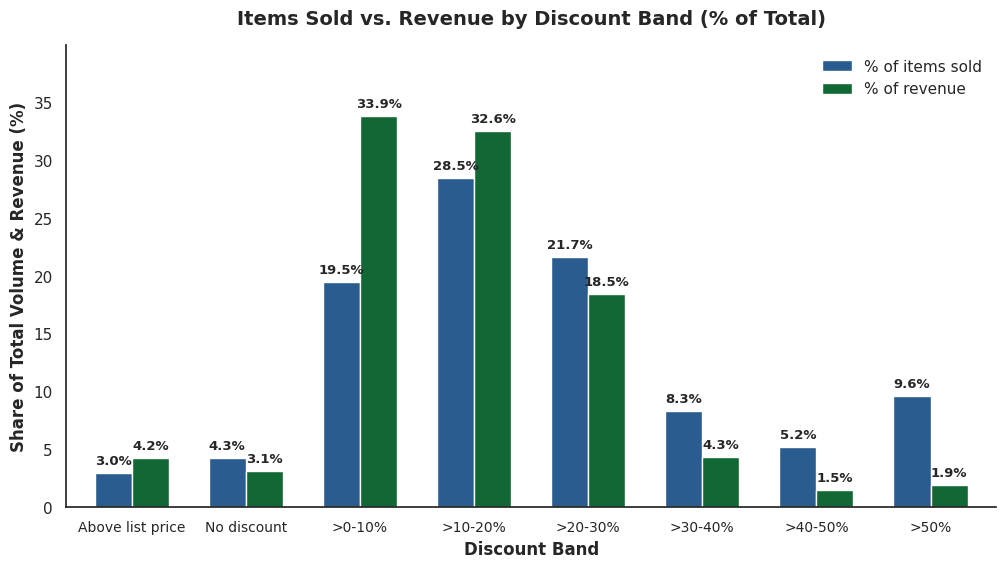

In [24]:
# chart 4: share of items sold (blue) and share of revenue (green) per discount band
ax = discount_bands.plot(kind="bar", y=["pct_items", "pct_revenue"], color=[BLUE, GREEN], figsize=(12, 6), width=0.65)
ax.set_title("Items Sold vs. Revenue by Discount Band (% of Total)", fontsize=14, fontweight="bold", pad=15)
sns.despine(top=True, right=True)

max_pct = max(discount_bands["pct_items"].max(), discount_bands["pct_revenue"].max())
ax.set_ylim(0, max_pct * 1.18)

# the exact % above each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9.5, fontweight="bold")

ax.set_ylabel("Share of Total Volume & Revenue (%)", fontsize=12, fontweight="bold")
ax.set_xlabel("Discount Band", fontsize=12, fontweight="bold")
ax.set_xticklabels(discount_bands.index, rotation=0, fontsize=10)
ax.legend(["% of items sold", "% of revenue"], loc="upper right", frameon=False, fontsize=11);

**Slide message:** about two thirds of revenue comes from discounts of up to 20%. Deeper discounts sell items but bring in little revenue.

## Summary

| Question | Answer (from the outputs above) |
|---|---|
| How many products are discounted? | 93% of order lines were sold below list price; 96% of the products sold were discounted at least once. |
| How big are the discounts? | 21.4% per order line on average (median 17.6%); 16.3% of the total list value (€1.53M). |
| Seasons and special dates | Sales and revenue peak in November (Black Friday) and December, then fall. The average discount stays at 15–25% all year. |
| Discounts by price | Under €50: 26% discount, 6% of revenue. €150–1,000: 10–16% discount, 71% of revenue. |
| Discounts by category | Accessories 29% discount, €0.70M; iPhones 9%, €1.33M; Storage & Memory 17.5%, €2.24M. |
| Discount size vs revenue | Discounts up to 20% bring in two thirds of revenue. |

**Recommendation (slide 7):** stop blanket discounting all year, lower discounts on items over €150 to about 10%, save big discounts for Black Friday, Christmas and old stock, and test changes on a small group of products first.

**Caveats:** no sales of €1,000 or more, no cost data (revenue, not profit), March 2017 mostly missing, March 2018 ends on the 14th.